In [1]:
import xarray as xr


In [2]:
import sys
sys.path.append('/glade/u/home/manishrv/documents/croc/dev/CrocoLens')
%load_ext autoreload
%autoreload 2
from CrocoLens.regional_domain import RegionalDomain
import matplotlib.pyplot as plt
import numpy as np
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy
import calendar

In [3]:
glorys_monthly_means = xr.open_dataset("/glade/derecho/scratch/manishrv/glorys_data/nwa_2000_monthly_means/glorys_monthly_means_regridded_to_nwa.nc")
cesm_monthly_means = xr.open_mfdataset("/glade/derecho/scratch/manishrv/archive/gustavo-glorys-2/ocn/hist/gustavo-glorys-2.mom6.h.native.2000*.nc")
hgrid = xr.open_dataset("/glade/derecho/scratch/manishrv/croc_input/gustavo-glorys-1/ocnice/ocean_hgrid.nc")

<GeoAxes: >

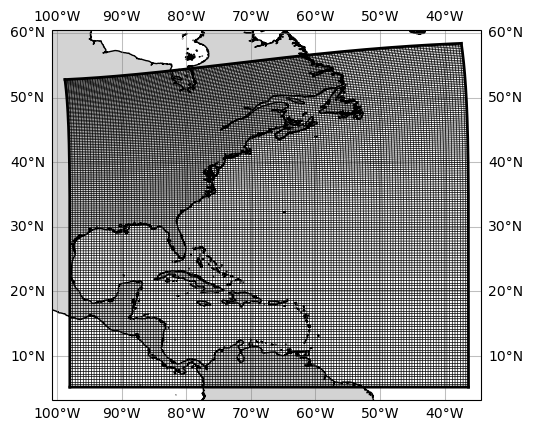

In [4]:
#Plot Raw
rd = RegionalDomain("/glade/derecho/scratch/manishrv/croc_input/gustavo-glorys-1/ocnice/ocean_hgrid.nc")
rd.plot_map()

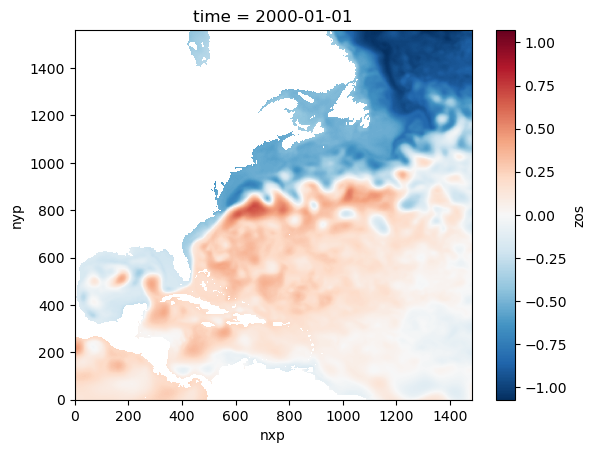

In [5]:
glorys_monthly_means.zos[0].plot()

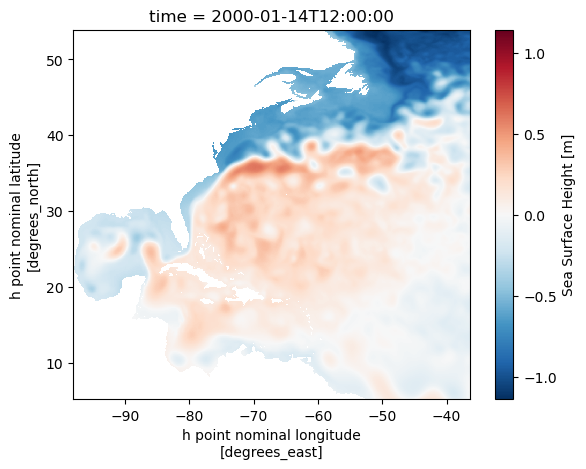

In [6]:
cesm_monthly_means.SSH[0].plot()

In [7]:
# Set Vars
glorys_var = "mlotst"
cesm_var = "mlotst"
output_var = "mlotst"
months = calendar.month_abbr[1:]
t_points = rd.get_point_type_dataset("t")
extent = [
                hgrid.x.min() - 2,
                hgrid.x.max() + 2,
                hgrid.y.min() - 2,
                hgrid.y.max() + 2,
            ]


In [8]:
diffs = xr.zeros_like(cesm_monthly_means["mlotst"])
for i, month in enumerate(months):
    # Get the data slice for the month
    cesm_month = cesm_monthly_means[cesm_var][i]
    glorys_month = glorys_monthly_means[glorys_var][i,t_points.t_points_y.values, t_points.t_points_x.values]
    # Rename glorys_month dims to xh, yh
    renamed_glorys= (glorys_month.rename({"nyp":"yh","nxp":"xh"}))
    diffs[i] = renamed_glorys - cesm_month


In [9]:
# fig, axes = plt.subplots(12, 3, figsize=(15, 30), subplot_kw={'projection': ccrs.PlateCarree()})
# fig.subplots_adjust(hspace=0, wspace=0)
# vmin = min(cesm_monthly_means[cesm_var].min(), glorys_monthly_means[glorys_var].min())
# vmax = max(cesm_monthly_means[cesm_var].max(), glorys_monthly_means[glorys_var].max())


# for i, month in enumerate(months):
#     # Get the data slice for the month
#     cesm_month = cesm_monthly_means[cesm_var][i]
#     glorys_month = glorys_monthly_means[glorys_var][i, t_points.t_points_y.values, t_points.t_points_x.values]
    
#     # Update coordinates
#     glorys_month = glorys_month.assign_coords({"y": glorys_month.nyp, "x": glorys_month.nxp})
    
#     diff_month = diffs[i]

#     for j, data in enumerate([cesm_month, glorys_month, diff_month]):
#         ax = axes[i, j]
        
#         # Set extent and aspect
#         ax.set_extent(extent, ccrs.PlateCarree())
#         ax.set_aspect('auto')
        
#         # Add land and coastlines
#         ax.add_feature(cartopy.feature.LAND, fc="lightgray")
#         ax.coastlines(resolution="10m")

#         # Plot the data
#         if j < 2:
#             im = ax.pcolormesh(
#                 cesm_monthly_means.xh, cesm_monthly_means.yh, data,
#                 transform=ccrs.PlateCarree(),
#                 vmin=0, vmax=400  # Shared colorbar range
#             )
#         else:
#             # Difference plot with its own colorbar
#             im_diff = ax.pcolormesh(
#                 cesm_monthly_means.xh, cesm_monthly_means.yh, data,
#                 transform=ccrs.PlateCarree(),   
#                 #vmin = -1.2, vmax = 1.2
#             )

#         # Add titles on the first row only
#         if i == 0:
#             ax.set_title(['CESM NWA', 'GLORYS', 'CESM NWA - GLORYS'][j], fontsize=12)
#         if j ==0:
#             ax.yaxis.set_visible(True)
#             ax.set_ylabel(month, fontsize=14, labelpad=20)

# # Add a colorbar
# cbar_ax1 = fig.add_axes([0.92, 0.5, 0.01, 0.4])
# fig.colorbar(im, cax=cbar_ax1, label="CESM/GLORYS Values")

# # Separate colorbar for difference plot
# cbar_ax2 = fig.add_axes([0.92, 0.05, 0.01, 0.4])
# fig.colorbar(im_diff, cax=cbar_ax2, label="Difference (CESM - GLORYS)")

# plt.show()      

<xarray.DataArray 'mlotst' ()>
dask.array<_nanmin_skip-aggregate, shape=(), dtype=float32, chunksize=(), chunktype=numpy.ndarray> <xarray.DataArray 'mlotst' ()>
array(1283.54016113)


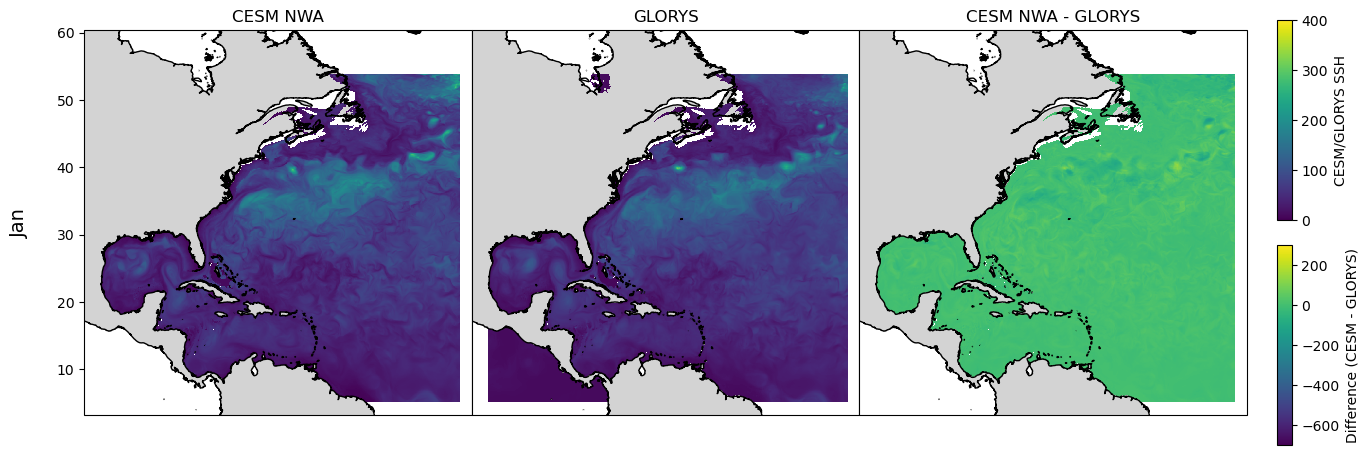

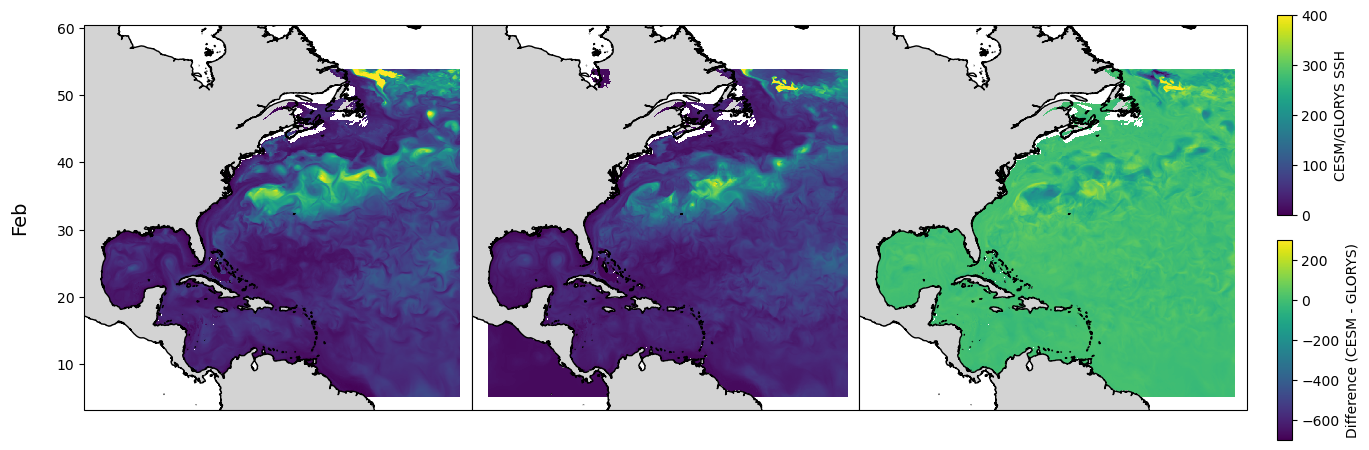

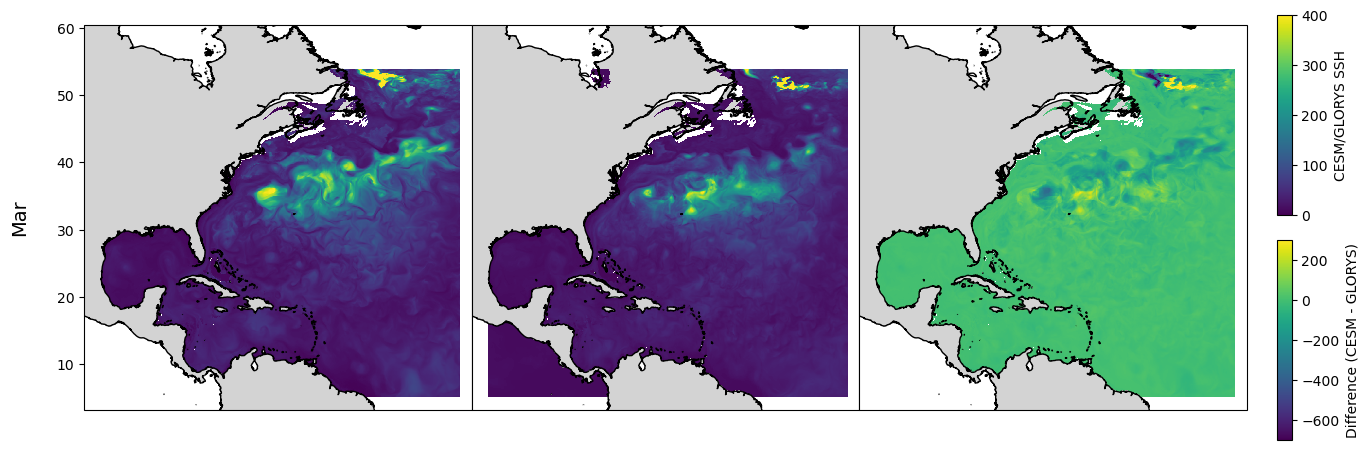

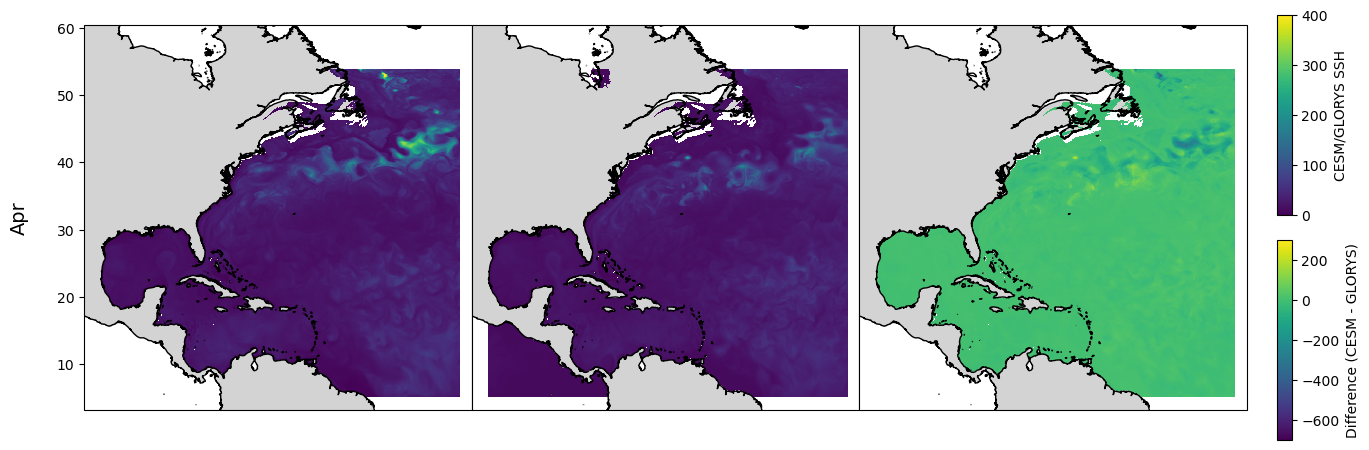

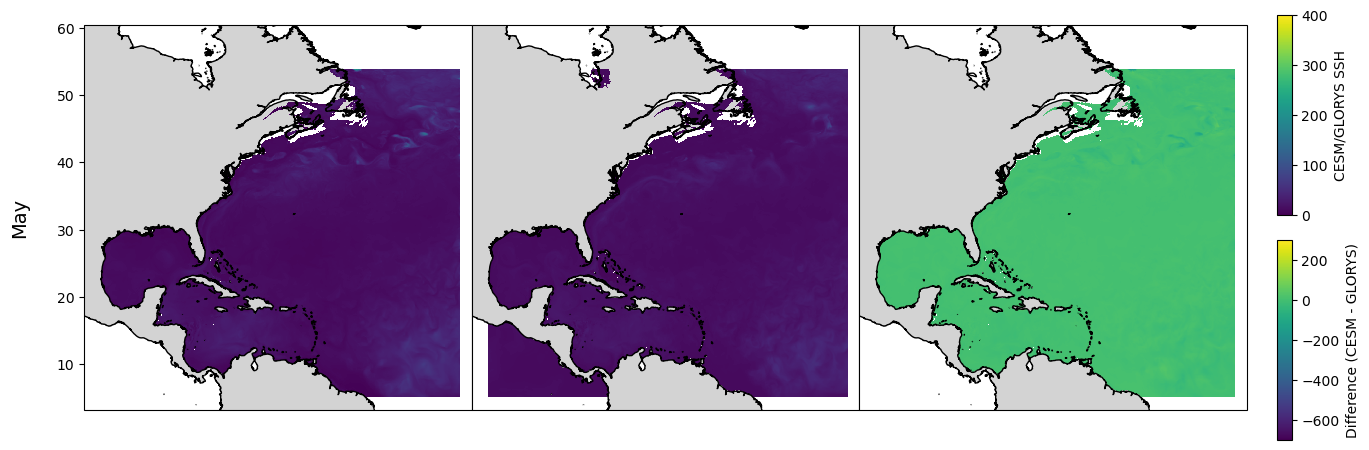

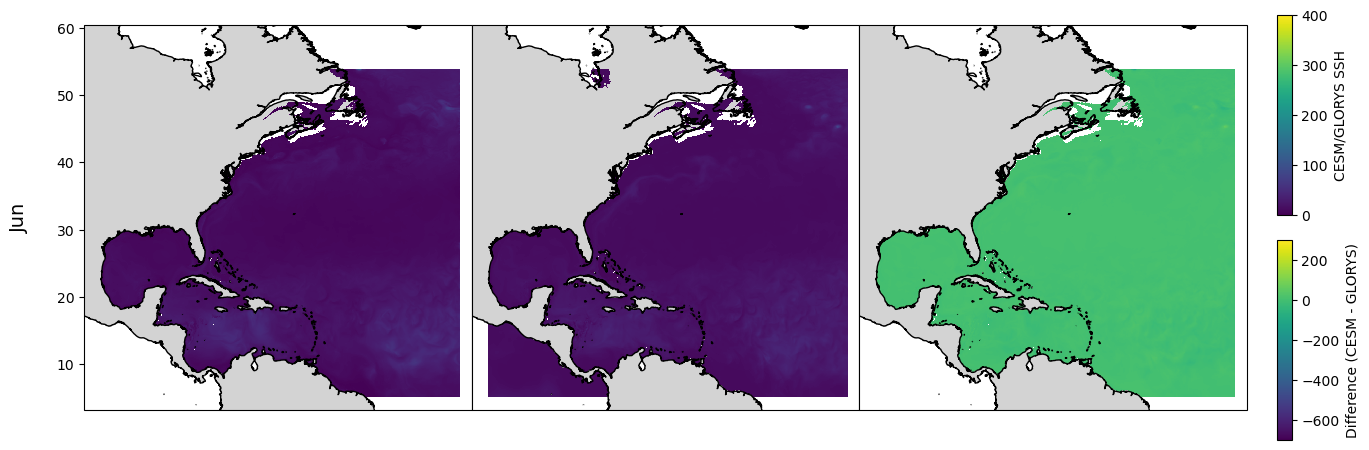

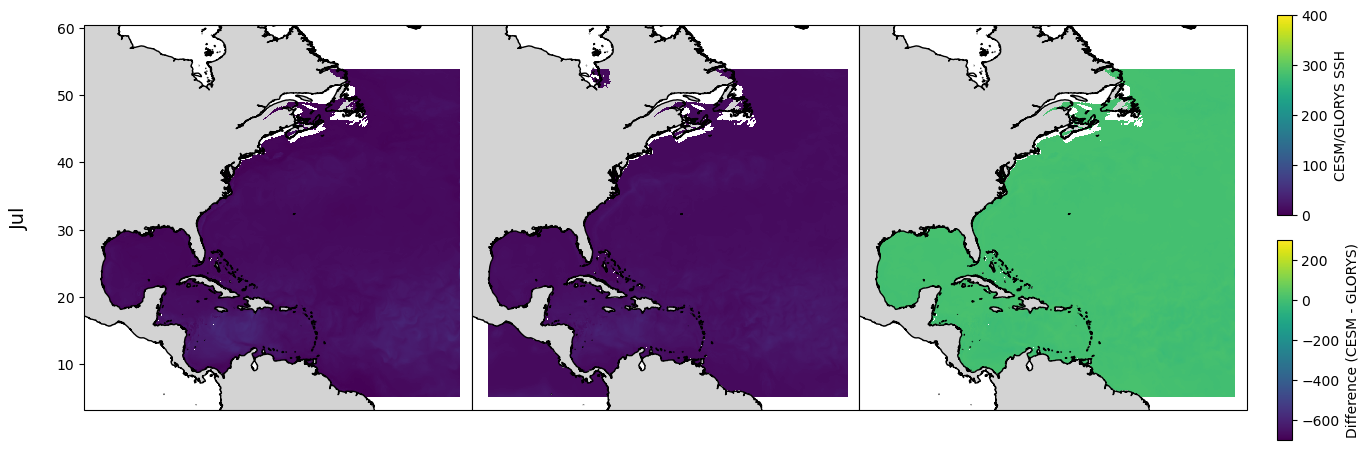

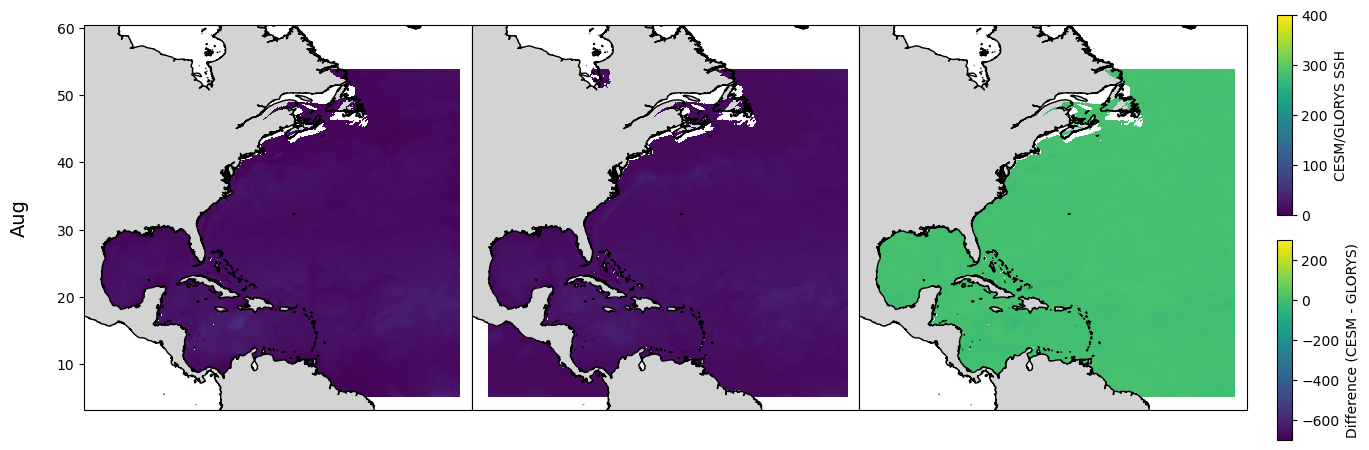

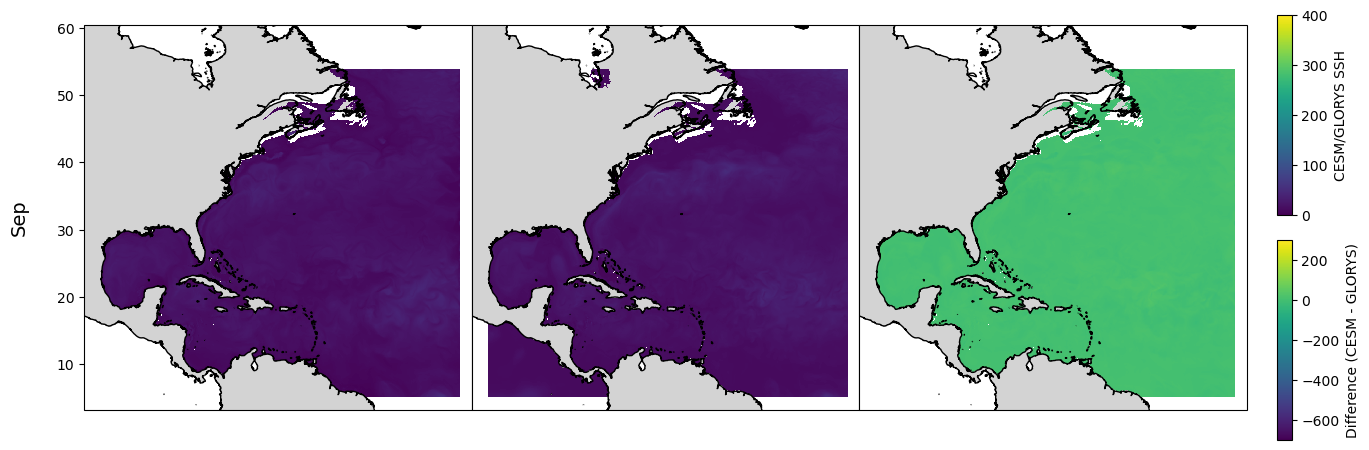

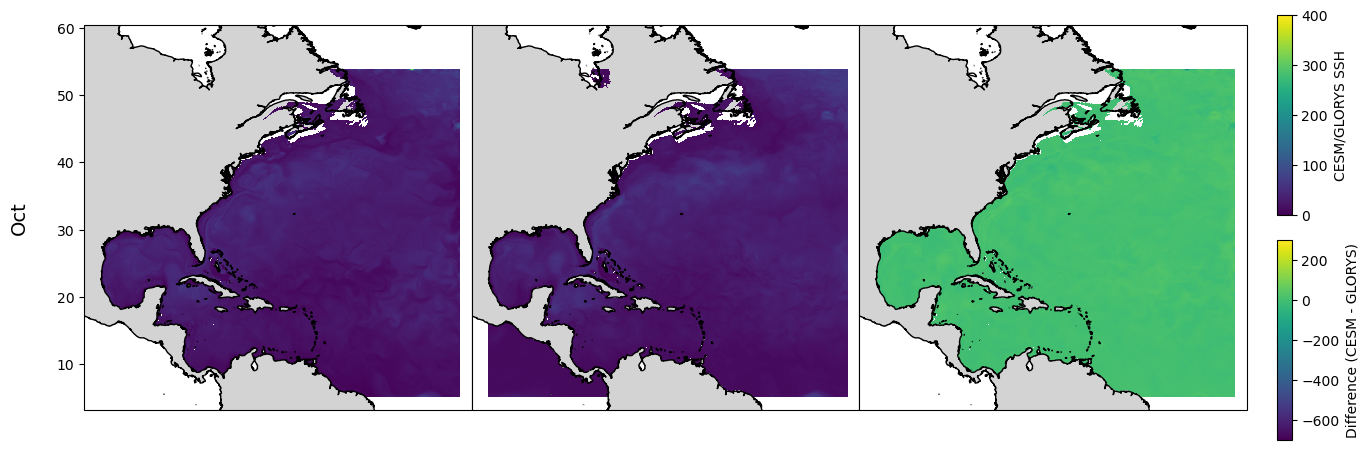

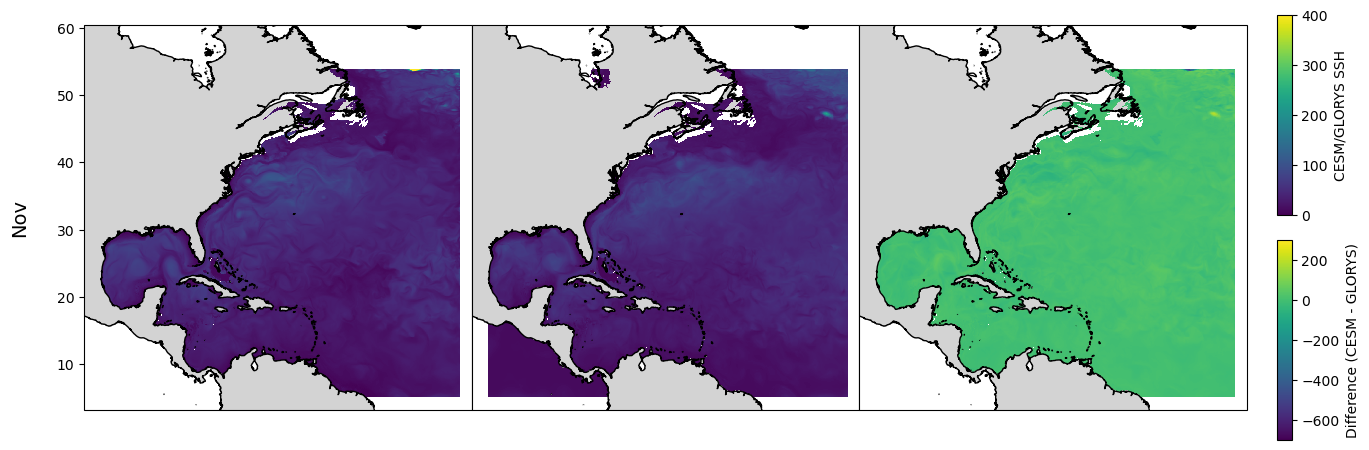

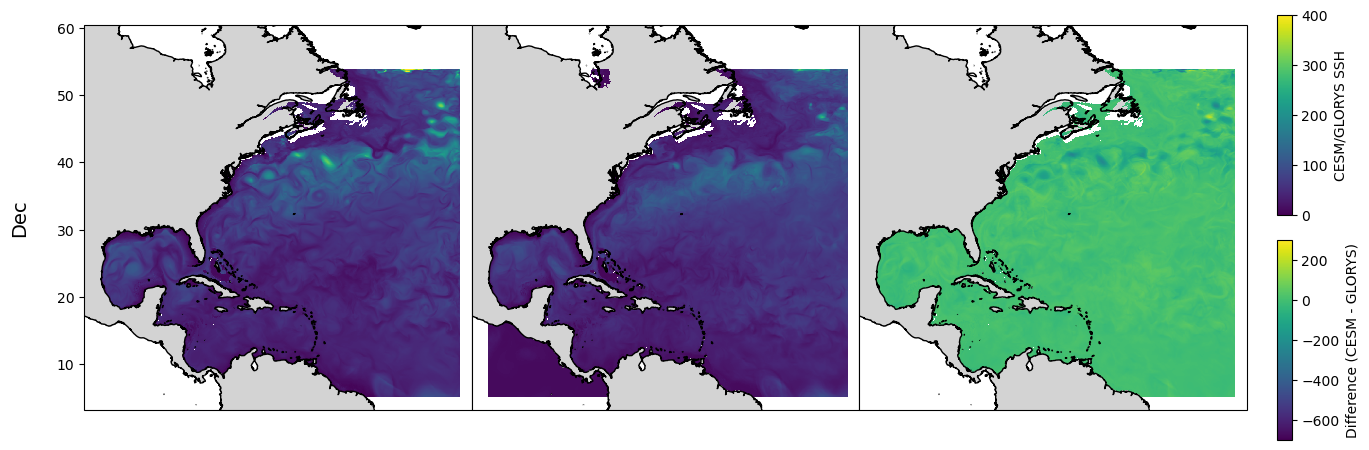

In [10]:

vmin = min(cesm_monthly_means[cesm_var].min(), glorys_monthly_means[glorys_var].min())
vmax = max(cesm_monthly_means[cesm_var].max(), glorys_monthly_means[glorys_var].max())
print(vmin, vmax)

for i, month in enumerate(months):
    fig, axes = plt.subplots(1, 3, figsize=(15, 5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.subplots_adjust(hspace=0, wspace=0)
    # Get the data slice for the month
    cesm_month = cesm_monthly_means[cesm_var][i]
    glorys_month = glorys_monthly_means[glorys_var][i, t_points.t_points_y.values, t_points.t_points_x.values]
    
    # Update coordinates
    glorys_month = glorys_month.assign_coords({"y": glorys_month.nyp, "x": glorys_month.nxp})
    
    diff_month = diffs[i]

    for j, data in enumerate([cesm_month, glorys_month, diff_month]):
        ax = axes[ j]
        
        # Set extent and aspect
        ax.set_extent(extent, ccrs.PlateCarree())
        ax.set_aspect('auto')
        
        # Add land and coastlines
        ax.add_feature(cartopy.feature.LAND, fc="lightgray")
        ax.coastlines(resolution="10m")

        # Plot the data
        if j < 2:
            im = ax.pcolormesh(
                cesm_monthly_means.xh, cesm_monthly_means.yh, data,
                transform=ccrs.PlateCarree(),
                vmin=0, vmax=400 # Shared colorbar range
            )
        else:
            # Difference plot with its own colorbar
            im_diff = ax.pcolormesh(
                cesm_monthly_means.xh, cesm_monthly_means.yh, data,
                transform=ccrs.PlateCarree(),   
               vmin = -700, vmax = 300
            )

        # Add titles on the first row only
        if i == 0:
            ax.set_title(['CESM NWA', 'GLORYS', 'CESM NWA - GLORYS'][j], fontsize=12)
        if j ==0:
            ax.yaxis.set_visible(True)
            ax.set_ylabel(month, fontsize=14, labelpad=20)

    # Add a colorbar
    cbar_ax1 = fig.add_axes([0.92, 0.5, 0.01, 0.4])
    fig.colorbar(im, cax=cbar_ax1, label="CESM/GLORYS SSH")
    # Separate colorbar for difference plot
    cbar_ax2 = fig.add_axes([0.92, 0.05, 0.01, 0.4])
    fig.colorbar(im_diff, cax=cbar_ax2, label="Difference (CESM - GLORYS)")
    plt.savefig("plots/glorys_vs_cesm/{}/monthly_plots/{:02d}_monthly_cesm_glorys_comparison_{}".format(output_var,i,month))

